Cell 1 — Load the data

In [3]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()

# If the notebook's working directory is not the project root,
# locate the project root using the data folder.
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

df = pd.read_csv(
    ROOT / "data" / "processed" / "orderguard_dataset.csv",
    parse_dates=["order_purchase_timestamp"],
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (96470, 29)


,order_id,order_purchase_timestamp,is_late,purchase_hour,purchase_day_of_week,purchase_month,purchase_is_weekend,promised_delivery_days,customer_state,item_count,...,product_height_mean,product_width_mean,dominant_category,dominant_seller_state,seller_customer_same_state_fraction,freight_to_price_ratio,payment_count,payment_value_sum,payment_installments_max,dominant_payment_type
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,0,10,0,10,0,16.0,SP,1,...,8.0,13.0,housewares,SP,1.0,0.290764,3.0,38.71,1.0,voucher
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,0,20,1,7,0,20.0,BA,1,...,13.0,19.0,perfumery,SP,0.0,0.191744,1.0,141.46,1.0,boleto
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,0,8,2,8,0,27.0,GO,1,...,19.0,21.0,auto,SP,0.0,0.120200,1.0,179.12,3.0,credit_card
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,0,19,5,11,1,27.0,RN,1,...,10.0,20.0,pet_shop,MG,0.0,0.604444,1.0,72.20,1.0,credit_card
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,0,21,1,2,0,13.0,SP,1,...,15.0,15.0,stationery,SP,1.0,0.438191,1.0,28.62,1.0,credit_card


Cell 2 — Inspect target balance

is_late
0    88644
1     7826
Name: count, dtype: int64

Class proportions:
is_late
0    0.9189
1    0.0811
Name: proportion, dtype: float64


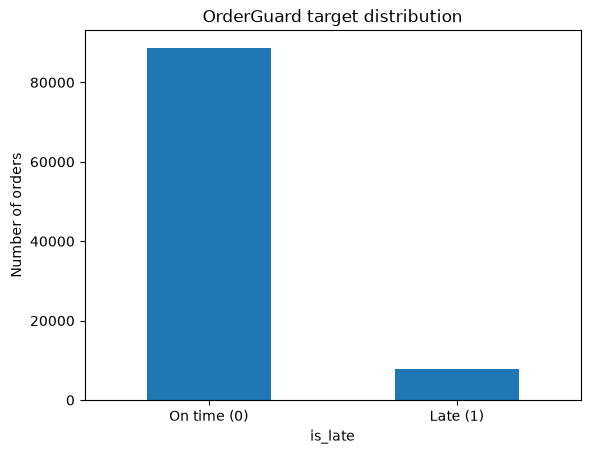

In [4]:
print(df["is_late"].value_counts())
print("\nClass proportions:")
print(df["is_late"].value_counts(normalize=True).round(4))

df["is_late"].value_counts().sort_index().plot(
    kind="bar",
    rot=0,
)
plt.xticks([0, 1], ["On time (0)", "Late (1)"], rotation=0)
plt.ylabel("Number of orders")
plt.title("OrderGuard target distribution")
plt.show()

Cell 3 — Compare late-delivery rates over time

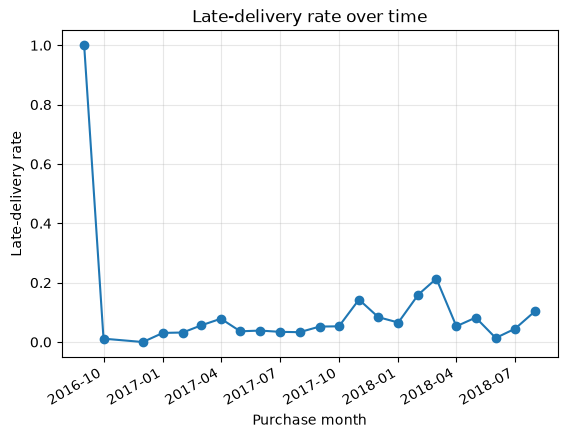

In [5]:
monthly_late_rate = (
    df.set_index("order_purchase_timestamp")
    .resample("MS")["is_late"]
    .mean()
    .dropna()
)

monthly_late_rate.plot(marker="o")
plt.ylabel("Late-delivery rate")
plt.xlabel("Purchase month")
plt.title("Late-delivery rate over time")
plt.grid(True, alpha=0.3)
plt.show()

Cell 4 — Compare numerical features by outcome

In [6]:
numeric_features = [
    "item_count",
    "distinct_sellers",
    "item_price_sum",
    "freight_sum",
    "payment_installments_max",
    "purchase_hour",
    "purchase_day_of_week",
]

for column in numeric_features:
    if column not in df.columns:
        continue

    comparison = df.groupby("is_late")[column].median()
    print(f"\n{column}")
    print(comparison.rename(index={0: "On time", 1: "Late"}))


item_count
is_late
On time    1.0
Late       1.0
Name: item_count, dtype: float64

distinct_sellers
is_late
On time    1.0
Late       1.0
Name: distinct_sellers, dtype: float64

item_price_sum
is_late
On time    85.5
Late       89.9
Name: item_price_sum, dtype: float64

freight_sum
is_late
On time    17.070
Late       18.055
Name: freight_sum, dtype: float64

payment_installments_max
is_late
On time    2.0
Late       2.0
Name: payment_installments_max, dtype: float64

purchase_hour
is_late
On time    15.0
Late       15.0
Name: purchase_hour, dtype: float64

purchase_day_of_week
is_late
On time    3.0
Late       2.5
Name: purchase_day_of_week, dtype: float64


Cell 5 — Monthly order counts alongside late-delivery rates

In [7]:
monthly = (
    df.set_index("order_purchase_timestamp")
    .resample("MS")
    .agg(
        order_count=("is_late", "size"),
        late_count=("is_late", "sum"),
        late_rate=("is_late", "mean"),
    )
)

monthly["late_rate_pct"] = monthly["late_rate"] * 100

monthly[["order_count", "late_count", "late_rate_pct"]].round(2)

,order_count,late_count,late_rate_pct
order_purchase_timestamp,,,
2016-09-01,1,1,100.00
2016-10-01,265,3,1.13
2016-11-01,0,0,NaN
2016-12-01,1,0,0.00
2017-01-01,750,23,3.07
2017-02-01,1653,53,3.21
2017-03-01,2546,142,5.58
2017-04-01,2303,181,7.86
2017-05-01,3545,128,3.61


Cell 6 — Plot monthly sample sizes

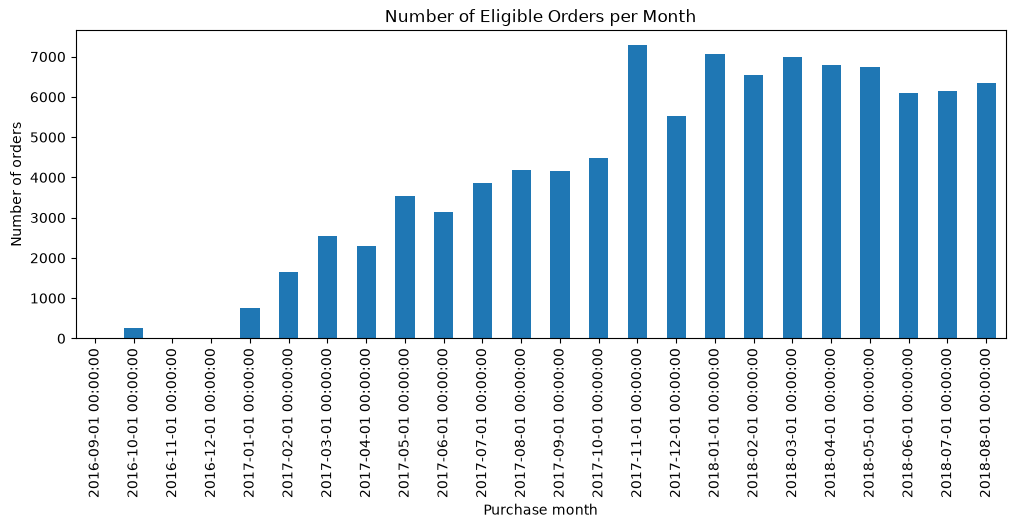

In [8]:
monthly["order_count"].plot(kind="bar", figsize=(12, 4))
plt.title("Number of Eligible Orders per Month")
plt.xlabel("Purchase month")
plt.ylabel("Number of orders")
plt.show()

Cell 7 — Compare feature distributions

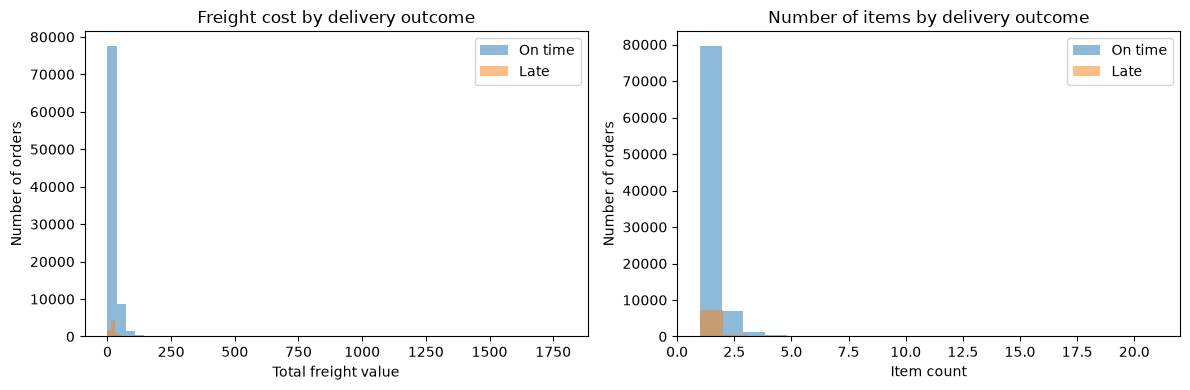

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for outcome, label in [(0, "On time"), (1, "Late")]:
    subset = df.loc[df["is_late"] == outcome, "freight_sum"]
    axes[0].hist(
        subset.dropna(),
        bins=50,
        alpha=0.5,
        label=label,
    )

    subset = df.loc[df["is_late"] == outcome, "item_count"]
    axes[1].hist(
        subset.dropna(),
        bins=20,
        alpha=0.5,
        label=label,
    )

axes[0].set_title("Freight cost by delivery outcome")
axes[0].set_xlabel("Total freight value")
axes[1].set_title("Number of items by delivery outcome")
axes[1].set_xlabel("Item count")

for ax in axes:
    ax.legend()
    ax.set_ylabel("Number of orders")

plt.tight_layout()
plt.show()

In [10]:
# Inspect the timing and missingness of the candidate feature.
print(
    df[
        [
            "order_purchase_timestamp",
            "promised_delivery_days",
            "is_late",
        ]
    ].describe(include="all")
)

print("\nPromised delivery days by outcome:")
print(
    df.groupby("is_late")["promised_delivery_days"]
    .agg(["count", "mean", "median", "min", "max"])
)

         order_purchase_timestamp  promised_delivery_days       is_late
count                       96470            96470.000000  96470.000000
mean   2018-01-01 23:17:43.624411               24.372738      0.081124
min           2016-09-15 12:16:38                3.000000      0.000000
25%    2017-09-14 08:56:46.500000               19.000000      0.000000
50%    2018-01-20 19:34:43.500000               24.000000      0.000000
75%    2018-05-05 18:29:50.250000               29.000000      0.000000
max           2018-08-29 15:00:37              156.000000      1.000000
std                           NaN                8.758428      0.273026

Promised delivery days by outcome:
         count       mean  median  min    max
is_late                                      
0        88644  24.528361    24.0  3.0  156.0
1         7826  22.610018    23.0  3.0   70.0
